<a href="https://colab.research.google.com/github/aditya01-dev/Natural-Language-Processing-Lab/blob/main/NLP_Practical_25_BERT_GPT2_Embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cpu

INPUT SENTENCES:
1. Artificial intelligence is transforming modern technology.
2. Machine learning is changing the world of technology.
3. The weather is pleasant and sunny today.
4. Deep learning uses neural networks for learning.
5. I enjoy reading books in my free time.


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (13 outputs left out)


GPT-2 COSINE SIMILARITY MATRIX:


,S1,S2,S3,S4,S5
S1,1.000,0.999,0.997,0.998,0.997
S2,0.999,1.000,0.997,0.999,0.997
S3,0.997,0.997,1.000,0.997,0.999
S4,0.998,0.999,0.997,1.000,0.997
S5,0.997,0.997,0.999,0.997,1.000



BERT VS GPT-2 SIMILARITY COMPARISON:


,Sentence 1,Sentence 2,BERT Similarity,GPT-2 Similarity
0,Artificial intelligence is transforming modern...,Machine learning is changing the world of tech...,0.932,0.999
1,Artificial intelligence is transforming modern...,The weather is pleasant and sunny today.,0.562,0.997
2,Artificial intelligence is transforming modern...,Deep learning uses neural networks for learning.,0.712,0.998
3,Artificial intelligence is transforming modern...,I enjoy reading books in my free time.,0.597,0.997
4,Machine learning is changing the world of tech...,The weather is pleasant and sunny today.,0.556,0.997
5,Machine learning is changing the world of tech...,Deep learning uses neural networks for learning.,0.731,0.999
6,Machine learning is changing the world of tech...,I enjoy reading books in my free time.,0.604,0.997
7,The weather is pleasant and sunny today.,Deep learning uses neural networks for learning.,0.446,0.997
8,The weather is pleasant and sunny today.,I enjoy reading books in my free time.,0.636,0.999
9,Deep learning uses neural networks for learning.,I enjoy reading books in my free time.,0.518,0.997


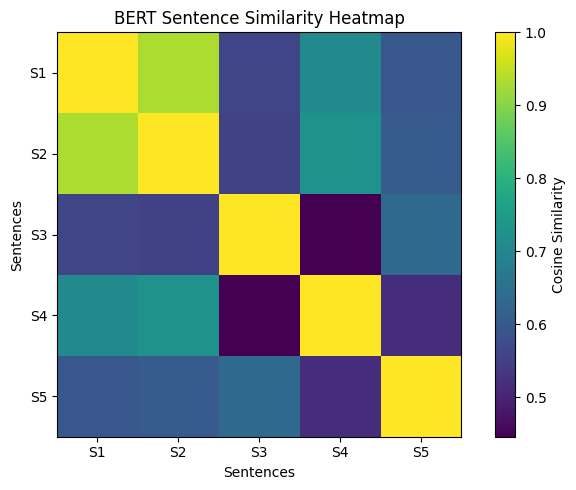

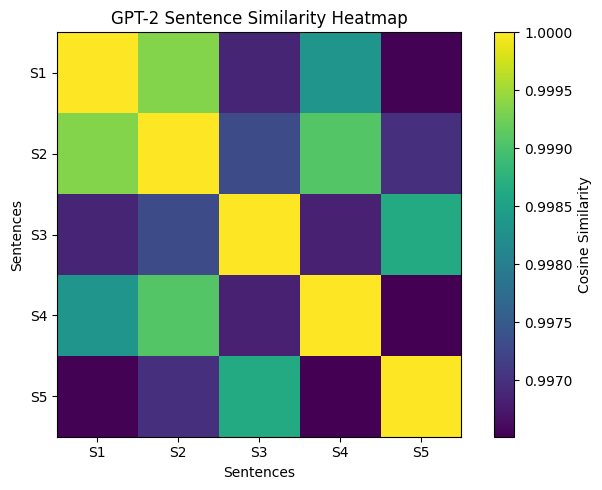

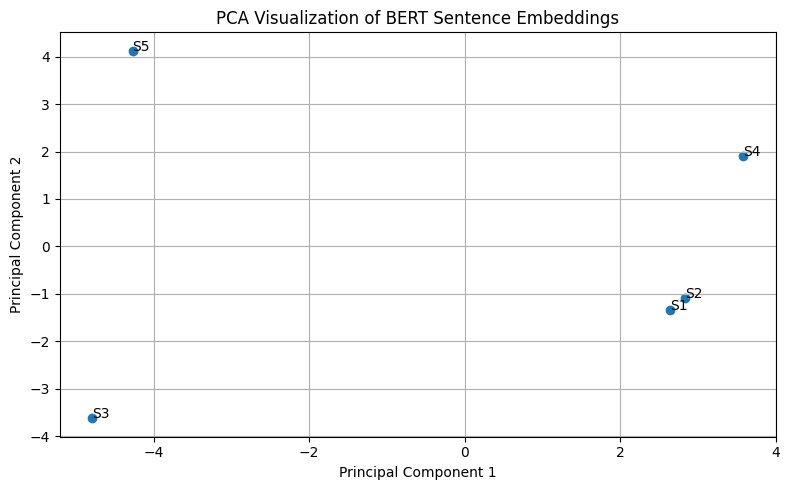


RESULT:
Sentence embeddings were generated using pretrained BERT
and GPT-2 models.

CONCLUSION:
Sentence embeddings represent text in numerical vector form.
Cosine similarity was used to compare sentence representations
and analyze semantic similarity.


In [ ]:
# ============================================================
# PRACTICAL 25: SENTENCE EMBEDDINGS USING BERT AND GPT-2
# Course Outcome: CO3
# ============================================================
# Name: Aditya kumar Singh
# OBJECTIVE:
# To generate sentence embeddings using pretrained BERT and GPT-2
# and compare sentence similarity using cosine similarity.

!pip -q install transformers scikit-learn

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from IPython.display import display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ------------------------------------------------------------
# 2. SAMPLE SENTENCES
# ------------------------------------------------------------

sentences = [
    "Artificial intelligence is transforming modern technology.",

    "Machine learning is changing the world of technology.",

    "The weather is pleasant and sunny today.",

    "Deep learning uses neural networks for learning.",

    "I enjoy reading books in my free time."
]

print("\nINPUT SENTENCES:")
for i, sentence in enumerate(sentences, 1):
    print(f"{i}. {sentence}")

# ------------------------------------------------------------
# 3. LOAD PRETRAINED BERT MODEL
# ------------------------------------------------------------

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name).to(device)
bert_model.eval()

# ------------------------------------------------------------
# 4. LOAD PRETRAINED GPT-2 MODEL
# ------------------------------------------------------------

gpt_name = "gpt2"

gpt_tokenizer = AutoTokenizer.from_pretrained(gpt_name)
gpt_model = AutoModel.from_pretrained(gpt_name).to(device)

# GPT-2 has no default padding token
gpt_tokenizer.pad_token = gpt_tokenizer.eos_token
gpt_model.config.pad_token_id = gpt_tokenizer.pad_token_id

gpt_model.eval()

# ------------------------------------------------------------
# 5. GENERATE SENTENCE EMBEDDINGS USING MEAN POOLING
# ------------------------------------------------------------

def generate_embeddings(model, tokenizer, texts):

    encoded = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model(**encoded)

    hidden_states = outputs.last_hidden_state

    # Mean pooling while ignoring padding tokens
    mask = encoded["attention_mask"].unsqueeze(-1).float()

    embeddings = (hidden_states * mask).sum(dim=1) / mask.sum(dim=1)

    return embeddings.cpu().numpy()

# ------------------------------------------------------------
# 6. GENERATE BERT EMBEDDINGS
# ------------------------------------------------------------

bert_embeddings = generate_embeddings(
    bert_model,
    bert_tokenizer,
    sentences
)

print("\nBERT EMBEDDINGS SHAPE:")
print(bert_embeddings.shape)

# ------------------------------------------------------------
# 7. GENERATE GPT-2 EMBEDDINGS
# ------------------------------------------------------------

gpt_embeddings = generate_embeddings(
    gpt_model,
    gpt_tokenizer,
    sentences
)

print("\nGPT-2 EMBEDDINGS SHAPE:")
print(gpt_embeddings.shape)

# ------------------------------------------------------------
# 8. COSINE SIMILARITY USING BERT
# ------------------------------------------------------------

bert_similarity = cosine_similarity(bert_embeddings)

bert_similarity_df = pd.DataFrame(
    bert_similarity,
    index=[f"S{i}" for i in range(1, len(sentences) + 1)],
    columns=[f"S{i}" for i in range(1, len(sentences) + 1)]
)

print("\nBERT COSINE SIMILARITY MATRIX:")
display(bert_similarity_df.round(3))

# ------------------------------------------------------------
# 9. COSINE SIMILARITY USING GPT-2
# ------------------------------------------------------------

gpt_similarity = cosine_similarity(gpt_embeddings)

gpt_similarity_df = pd.DataFrame(
    gpt_similarity,
    index=[f"S{i}" for i in range(1, len(sentences) + 1)],
    columns=[f"S{i}" for i in range(1, len(sentences) + 1)]
)

print("\nGPT-2 COSINE SIMILARITY MATRIX:")
display(gpt_similarity_df.round(3))

# ------------------------------------------------------------
# 10. COMPARE EMBEDDING SIMILARITY
# ------------------------------------------------------------

comparison = []

for i in range(len(sentences)):
    for j in range(i + 1, len(sentences)):
        comparison.append({
            "Sentence 1": sentences[i],
            "Sentence 2": sentences[j],
            "BERT Similarity": bert_similarity[i, j],
            "GPT-2 Similarity": gpt_similarity[i, j]
        })

comparison_df = pd.DataFrame(comparison)

print("\nBERT VS GPT-2 SIMILARITY COMPARISON:")
display(comparison_df.round(3))

# ------------------------------------------------------------
# 11. VISUALIZE BERT SIMILARITY
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.imshow(bert_similarity, cmap="viridis")
plt.colorbar(label="Cosine Similarity")

plt.xticks(range(len(sentences)), [f"S{i}" for i in range(1, 6)])
plt.yticks(range(len(sentences)), [f"S{i}" for i in range(1, 6)])

plt.title("BERT Sentence Similarity Heatmap")
plt.xlabel("Sentences")
plt.ylabel("Sentences")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. VISUALIZE GPT-2 SIMILARITY
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.imshow(gpt_similarity, cmap="viridis")
plt.colorbar(label="Cosine Similarity")

plt.xticks(range(len(sentences)), [f"S{i}" for i in range(1, 6)])
plt.yticks(range(len(sentences)), [f"S{i}" for i in range(1, 6)])

plt.title("GPT-2 Sentence Similarity Heatmap")
plt.xlabel("Sentences")
plt.ylabel("Sentences")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. PCA VISUALIZATION OF BERT EMBEDDINGS
# ------------------------------------------------------------

pca = PCA(n_components=2)

bert_2d = pca.fit_transform(bert_embeddings)

plt.figure(figsize=(8, 5))

plt.scatter(bert_2d[:, 0], bert_2d[:, 1])

for i, sentence in enumerate(sentences):
    plt.annotate(
        f"S{i+1}",
        (bert_2d[i, 0], bert_2d[i, 1])
    )

plt.title("PCA Visualization of BERT Sentence Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 14. RESULT AND CONCLUSION
# ------------------------------------------------------------

print("\nRESULT:")
print("Sentence embeddings were generated using pretrained BERT")
print("and GPT-2 models.")

print("\nCONCLUSION:")
print("Sentence embeddings represent text in numerical vector form.")
print("Cosine similarity was used to compare sentence representations")
print("and analyze semantic similarity.")